# Miniproject 1: Brain neural activity related to language tasks

In [1]:
import os
import os.path as op
import glob
from pathlib import Path
import subprocess

os.chdir(next(Path.cwd().rglob("GROUP1_code.ipynb")).parent)

from utils import loadFSL, FSLeyesServer, mkdir_no_exist
# Loading fsl within Neurodesk
import module as lmod
await lmod.purge(force=True)
await lmod.load('fsl/6.0.7.18')
await lmod.load('freesurfer/7.4.1')
await lmod.list()

# FSL configuration
loadFSL()

# Libraries for Part 1 1)
await lmod.load("ants/2.6.5")
from fsl.wrappers import bet, fast, flirt
import nibabel as nib
import numpy as np
import pandas as pd
from nilearn import plotting
import matplotlib.pyplot as plt

In [3]:
%gui wx

In [5]:
# Start FSLeyes 
fsleyesDisplay = FSLeyesServer()
fsleyesDisplay.show()

## 0. Download Dataset

In [6]:
# Raw data (downloaded from Google Drive, never modified)
data_root = "raw_data"
t1_path    = op.join(data_root, "T1", "T1w.nii.gz")
fmri_path  = op.join(data_root, "fMRI", "tfMRI_LANGUAGE_LR", "tfMRI_LANGUAGE_LR.nii.gz")
onset_path = op.join(data_root, "fMRI", "tfMRI_LANGUAGE_LR", "tfMRI_LANGUAGE_LR_task_onsets.csv")

for p in (t1_path, fmri_path, onset_path):
    print(op.exists(p), p)

# Outputs: everything we produce goes in derivatives/, to keep raw data clean
deriv_root = "derivatives"
anat_out = op.join(deriv_root, "anat")  
func_out = op.join(deriv_root, "func")   
mkdir_no_exist(anat_out)
mkdir_no_exist(func_out)

True raw_data/T1/T1w.nii.gz
True raw_data/fMRI/tfMRI_LANGUAGE_LR/tfMRI_LANGUAGE_LR.nii.gz
True raw_data/fMRI/tfMRI_LANGUAGE_LR/tfMRI_LANGUAGE_LR_task_onsets.csv


In [7]:
# Download raw datas (header only)
t1_img   = nib.load(t1_path)
fmri_img = nib.load(fmri_path)

# Raw data inspection
print("T1w")
print("  shape      :", t1_img.shape)
print("  voxel (mm) :", t1_img.header.get_zooms())
print("  orientation:", nib.aff2axcodes(t1_img.affine))

print("fMRI")
print("  shape      :", fmri_img.shape)
print("  voxel (mm) + TR (s):", fmri_img.header.get_zooms())
print("  orientation:", nib.aff2axcodes(fmri_img.affine))

# Task timing
onsets = pd.read_csv(onset_path)
print(onsets.head(10))

T1w
  shape      : (260, 311, 260)
  voxel (mm) : (np.float32(0.7), np.float32(0.7), np.float32(0.7))
  orientation: ('L', 'A', 'S')
fMRI
  shape      : (91, 109, 91, 316)
  voxel (mm) + TR (s): (np.float32(2.0), np.float32(2.0), np.float32(2.0), np.float32(0.72))
  orientation: ('L', 'A', 'S')
    onset  duration      trial_type
0   0.241    28.270           story
1   0.241    20.445   present_story
2  21.192     1.161  question_story
3  25.550     2.961  response_story
4  28.696     0.727             cue
5  30.095     5.667    present_math
6  30.095    12.241            math
7  35.946     3.391   question_math
8  39.371     2.965   response_math
9  42.570     5.453    present_math


### Data inspection

| Property | T1w | fMRI (tfMRI_LANGUAGE_LR) |
|---|---|---|
| Matrix size | 260 × 311 × 260 | 91 × 109 × 91 × 316 volumes |
| Voxel size | 0.7 mm isotropic | 2 mm isotropic |
| TR | – | 0.72 s |
| Orientation | LAS | LAS |

- **T1w**: high-resolution (0.7 mm) anatomical image in the subject's native space
  - -> need to register it to MNI space (Part 1.1c).
- **fMRI**: the 91 × 109 × 91 grid at 2 mm matches the MNI152 2 mm template, indicating that the functional data are already in MNI space (consistent with the HCP minimal preprocessing pipeline). 
  - -> relevant for Part 1.2c, where registering the fMRI to MNI may not be needed.
- **Run duration**: 316 volumes × 0.72 s ≈ 227 s ≈ 3.8 min
  - -> consistent with the run length reported in the task description.
- **TR**: 0.72 s (multiband acquisition)
  - -> required for the GLM design matrix.
- **Orientation**: both images share the same axis orientation (LAS)
  - -> no reorientation is needed.

## 1. Structural preprocessing

### 1.a. Skull-stripping

In [8]:
# Skull-stripping with BET
# Test different masks to see which one best
"""
variants = {
    "default" : [],          # default -f fractional intensity threshold : 0.5
    "f04":  ["-f", "0.4"],   # change -f fractional intensity threshold to 0.4
    "R":    ["-R"],          # robust centre estimation alone (default threshold 0.5)
    "f045": ["-f", "0.45"],  # intermediate threshold
    "g01":  ["-g", "0.1"],   # larger brain at the bottom, smaller at the top
    "g02":  ["-g", "0.2"],
}

for name, opts in variants.items():
    out = op.join(anat_out, f"T1w_brain_{name}.nii.gz")
    print("Running BET", name, opts)
    subprocess.run(["bet", t1_path, out, "-m"] + opts, check=True)

fsleyesDisplay.resetOverlays()
fsleyesDisplay.load(t1_path)

# Masks to compare: name -> colour
masks = {
    "default": "red",
    "f04":     "blue",
    "R":       "green",
    "f045":    "yellow",
    "g01":     "pink",
    "g02":     "cool",
}

for i, (name, cmap) in enumerate(masks.items(), start=1):
    fsleyesDisplay.load(op.join(anat_out, f"T1w_brain_{name}_mask.nii.gz"))
    overlay = fsleyesDisplay.overlayList[i]
    fsleyesDisplay.displayCtx.getOpts(overlay).cmap = cmap
    display = fsleyesDisplay.displayCtx.getDisplay(overlay)
    display.alpha = 40
    display.enabled = name in ("default", "f04")   # only show 2 masks at first
"""

'\nvariants = {\n    "default" : [],          # default -f fractional intensity threshold : 0.5\n    "f04":  ["-f", "0.4"],   # change -f fractional intensity threshold to 0.4\n    "R":    ["-R"],          # robust centre estimation alone (default threshold 0.5)\n    "f045": ["-f", "0.45"],  # intermediate threshold\n    "g01":  ["-g", "0.1"],   # larger brain at the bottom, smaller at the top\n    "g02":  ["-g", "0.2"],\n}\n\nfor name, opts in variants.items():\n    out = op.join(anat_out, f"T1w_brain_{name}.nii.gz")\n    print("Running BET", name, opts)\n    subprocess.run(["bet", t1_path, out, "-m"] + opts, check=True)\n\nfsleyesDisplay.resetOverlays()\nfsleyesDisplay.load(t1_path)\n\n# Masks to compare: name -> colour\nmasks = {\n    "default": "red",\n    "f04":     "blue",\n    "R":       "green",\n    "f045":    "yellow",\n    "g01":     "pink",\n    "g02":     "cool",\n}\n\nfor i, (name, cmap) in enumerate(masks.items(), start=1):\n    fsleyesDisplay.load(op.join(anat_out, f"T1

In [9]:
# RUN: Selected mask: Robust brain centre estimation, default threshold (f = 0.5)
t1_brain_R  = op.join(anat_out, "T1w_brain_R.nii.gz")
subprocess.run(["bet", t1_path, t1_brain_R, "-R", "-m"], check=True)

CompletedProcess(args=['bet', 'raw_data/T1/T1w.nii.gz', 'derivatives/anat/T1w_brain_R.nii.gz', '-R', '-m'], returncode=0)

In [10]:
fsleyesDisplay.resetOverlays()
fsleyesDisplay.load(t1_path)
fsleyesDisplay.load(t1_brain_R)

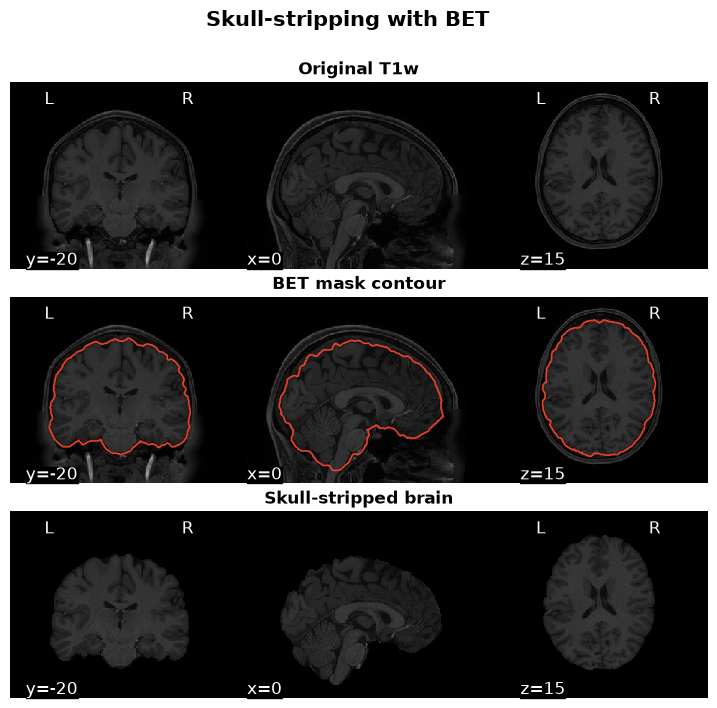

In [11]:
# Figure for 1.1a: original T1w, mask contour, skull-stripped brain
fig_dir = "figures"
mkdir_no_exist(fig_dir)

CUT = (0, -20, 15)

t1_brain = op.join(anat_out, "T1w_brain_R.nii.gz")
t1_mask  = op.join(anat_out, "T1w_brain_R_mask.nii.gz")

rows = ["Original T1w", "BET mask contour", "Skull-stripped brain"]

fig, axes = plt.subplots(3, 1, figsize=(9, 8))
fig.subplots_adjust(hspace=0.15)

plotting.plot_anat(t1_path, axes=axes[0], cut_coords=CUT, draw_cross=False, black_bg=True)

disp = plotting.plot_anat(t1_path, axes=axes[1], cut_coords=CUT, draw_cross=False, black_bg=True)
disp.add_contours(t1_mask, levels=[0.5], colors="#E8412C", linewidths=1.2)

plotting.plot_anat(t1_brain, axes=axes[2], cut_coords=CUT, draw_cross=False, black_bg=True)

# Centered title above each row
for ax, label in zip(axes, rows):
    ax.text(0.5, 1.02, label, transform=ax.transAxes,
            ha="center", va="bottom", fontsize=12, fontweight="bold")

fig.suptitle("Skull-stripping with BET", fontsize=15, fontweight="bold", y=0.97)

fig.savefig(op.join(fig_dir, "1a_skull_stripping.png"), dpi=300, bbox_inches="tight")
plt.show()

## 1b. Tissue segmentation

In [12]:
# RUN Tissue segmentation with FAST (on the skull-stripped brain)
t1_brain = op.join(anat_out, "T1w_brain_R.nii.gz")   
segmentation_path = op.join(anat_out, "T1w_fast")                 

subprocess.run(["fast", "-n", "3", "-o", segmentation_path, t1_brain], check=True)

CompletedProcess(args=['fast', '-n', '3', '-o', 'derivatives/anat/T1w_fast', 'derivatives/anat/T1w_brain_R.nii.gz'], returncode=0)

In [13]:
fsleyesDisplay.resetOverlays()
fsleyesDisplay.load(t1_brain)
fsleyesDisplay.load(segmentation_path + "_seg.nii.gz")

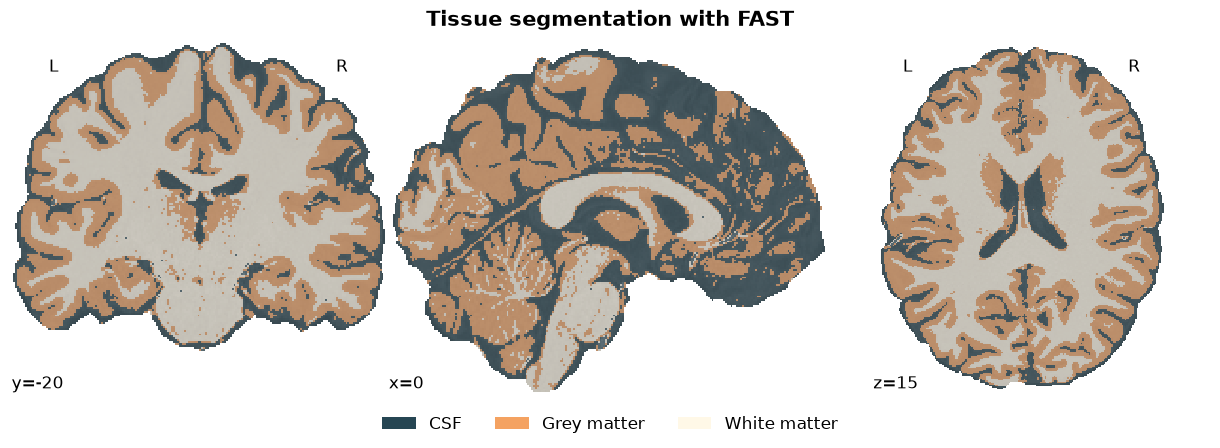

In [14]:
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

seg_path = segmentation_path + "_seg.nii.gz"

CUT = (0, -20, 15)

# One colour per tissue class (label 1 = CSF, 2 = GM, 3 = WM)
tissues = ["CSF", "Grey matter", "White matter"]
colors = ["#264653", "#F4A261", "#FFF8E7"]
cmap = ListedColormap(colors)

fig = plt.figure(figsize=(12, 4.5))
ax = fig.add_axes([0, 0.12, 1, 0.78])     # leave room for the title and the legend

plotting.plot_roi(seg_path, bg_img=t1_brain, cmap=cmap, vmin=1, vmax=3,
                  alpha=0.55, cut_coords=(0, -20, 15), draw_cross=False,
                  black_bg=False, axes=ax, figure=fig)

fig.suptitle("Tissue segmentation with FAST", fontsize=15, fontweight="bold", y=0.97)
fig.legend(handles=[Patch(facecolor=c, label=t) for c, t in zip(colors, tissues)],
           loc="lower center", ncol=3, frameon=False, fontsize=12)

fig.savefig(op.join(fig_dir, "1b_segmentation.png"), dpi=300, bbox_inches="tight")
plt.show()

## 1b. Registration

In [15]:
# Linear (affine) registration of the T1 to MNI space with FLIRT
source    = op.join(anat_out, "T1w_brain_R.nii.gz")   
reference = op.expandvars(op.join("$FSLDIR", "data", "standard", "MNI152_T1_1mm_brain.nii.gz"))  
result    = op.join(anat_out, "T1w_mni")

costs_to_consider = ["leastsq", "normcorr", "corratio"]

for c in costs_to_consider:
    subprocess.run(["flirt", "-in", source, "-ref", reference,
                    "-out", result + "_" + c,
                    "-omat", result + "_" + c + ".mat",
                    "-cost", c], check=True)

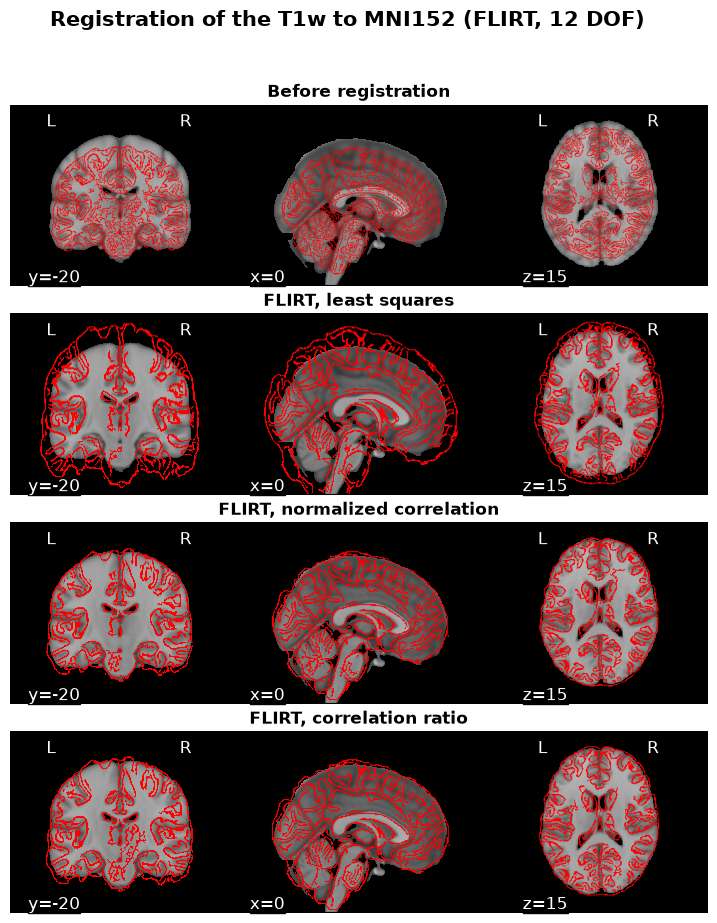

In [16]:
labels = ["Before registration", "FLIRT, least squares",
          "FLIRT, normalized correlation", "FLIRT, correlation ratio"]
images = [source] + [result + "_" + c + ".nii.gz" for c in ["leastsq", "normcorr", "corratio"]]

fig, axes = plt.subplots(4, 1, figsize=(9, 10.5))
fig.subplots_adjust(hspace=0.15)

for ax, img, label in zip(axes, images, labels):
    disp = plotting.plot_anat(reference, axes=ax, cut_coords=CUT,
                              draw_cross=False, black_bg=True)
    disp.add_edges(img, color="r")
    ax.text(0.5, 1.02, label, transform=ax.transAxes,
            ha="center", va="bottom", fontsize=12, fontweight="bold")

fig.suptitle("Registration of the T1w to MNI152 (FLIRT, 12 DOF)",
             fontsize=15, fontweight="bold", y=0.97)
fig.savefig(op.join(fig_dir, "1c_registration_costs.png"), dpi=300, bbox_inches="tight")
plt.show()

In [17]:
ref_data = nib.load(reference).get_fdata()
brain = ref_data > 0
for c in costs_to_consider:
    reg = nib.load(result + "_" + c + ".nii.gz").get_fdata()
    r = np.corrcoef(reg[brain], ref_data[brain])[0, 1]
    print(f"{c:10s} correlation with MNI: {r:.3f}")

leastsq    correlation with MNI: 0.483
normcorr   correlation with MNI: 0.625
corratio   correlation with MNI: 0.622


In [18]:
# RUN
syn_full_prefix = op.join(anat_out, "T1w_to_mni_synfull_")
subprocess.run(["antsRegistrationSyN.sh", "-d", "3", "-f", reference,
                "-m", op.join(anat_out, "T1w_brain_R.nii.gz"),
                "-t", "s", "-n", "4", "-o", syn_full_prefix], check=True)


--------------------------------------------------------------------------------------
 Mapping parameters
--------------------------------------------------------------------------------------
 Dimensionality:           3
 Output name prefix:       derivatives/anat/T1w_to_mni_synfull_
 Fixed images:             /cvmfs/neurodesk.ardc.edu.au/containers/fsl_6.0.7.18_20250928/fsl_6.0.7.18_20250928.simg/opt/fsl-6.0.7.18//data/standard/MNI152_T1_1mm_brain.nii.gz
 Moving images:            derivatives/anat/T1w_brain_R.nii.gz
 Mask images:              
 Initial transforms:       
 Number of threads:        4
 Spline distance:          26
 Linear gradient step:     0.1
 SyN gradient step:        0.2
 Transform type:           s
 CC radius:                2
 Precision:                d
 Use histogram matching    0
 Repro                     0
 antsRegistration call:
--------------------------------------------------------------------------------------
antsRegistration --verbose 1 --dimensiona

CompletedProcess(args=['antsRegistrationSyN.sh', '-d', '3', '-f', '/cvmfs/neurodesk.ardc.edu.au/containers/fsl_6.0.7.18_20250928/fsl_6.0.7.18_20250928.simg/opt/fsl-6.0.7.18//data/standard/MNI152_T1_1mm_brain.nii.gz', '-m', 'derivatives/anat/T1w_brain_R.nii.gz', '-t', 's', '-n', '4', '-o', 'derivatives/anat/T1w_to_mni_synfull_'], returncode=0)

In [21]:
ref_data = nib.load(reference).get_fdata()
brain = ref_data > 0

for name in ["T1w_mni_normcorr", "T1w_to_mni_synfull_Warped"]:
    reg_data = nib.load(op.join(anat_out, name + ".nii.gz")).get_fdata()
    r = np.corrcoef(reg_data[brain], ref_data[brain])[0, 1]
    print(f"{name:28s} correlation with MNI: {r:.3f}")

T1w_mni_normcorr             correlation with MNI: 0.625
T1w_to_mni_synfull_Warped    correlation with MNI: 0.862


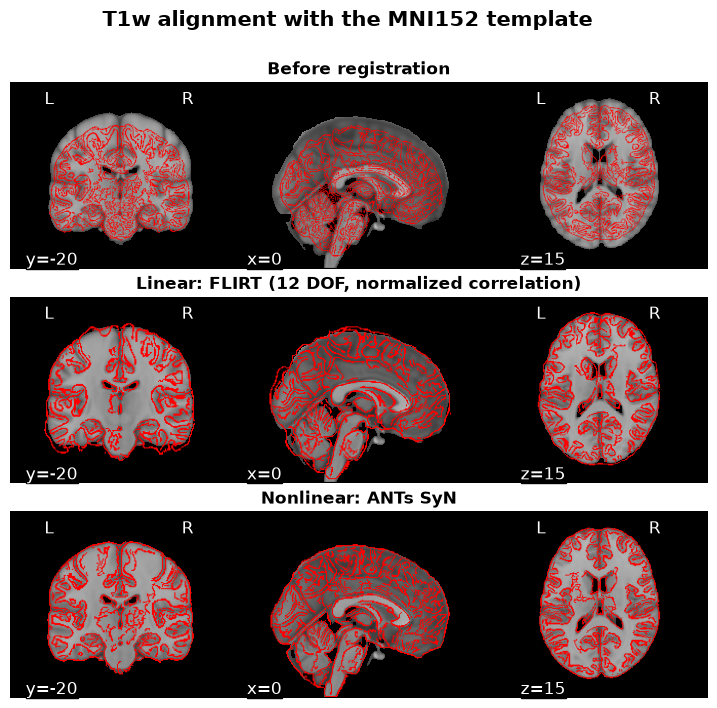

In [22]:
labels = ["Before registration",
          "Linear: FLIRT (12 DOF, normalized correlation)",
          "Nonlinear: ANTs SyN"]
images = [source,
          op.join(anat_out, "T1w_mni_normcorr.nii.gz"),
          op.join(anat_out, "T1w_to_mni_synfull_Warped.nii.gz")]

fig, axes = plt.subplots(3, 1, figsize=(9, 8))
fig.subplots_adjust(hspace=0.15)

for ax, img, label in zip(axes, images, labels):
    disp = plotting.plot_anat(reference, axes=ax, cut_coords=CUT,
                              draw_cross=False, black_bg=True)
    disp.add_edges(img, color="r")
    ax.text(0.5, 1.02, label, transform=ax.transAxes,
            ha="center", va="bottom", fontsize=12, fontweight="bold")

fig.suptitle("T1w alignment with the MNI152 template", fontsize=15, fontweight="bold", y=0.97)
fig.savefig(op.join(fig_dir, "1c_registration.png"), dpi=300, bbox_inches="tight")
plt.show()

In [23]:
jac_path = op.join(anat_out, "T1w_to_mni_synfull_jacobian.nii.gz")
subprocess.run(["CreateJacobianDeterminantImage", "3",
                syn_full_prefix + "1Warp.nii.gz", jac_path, "0", "0"], check=True)

jac = nib.load(jac_path).get_fdata()[brain]
print(f"Jacobian: min = {jac.min():.2f}, max = {jac.max():.2f}, "
      f"1st-99th percentile = [{np.percentile(jac, 1):.2f}, {np.percentile(jac, 99):.2f}]")

Jacobian: min = 0.08, max = 7.23, 1st-99th percentile = [0.35, 2.32]


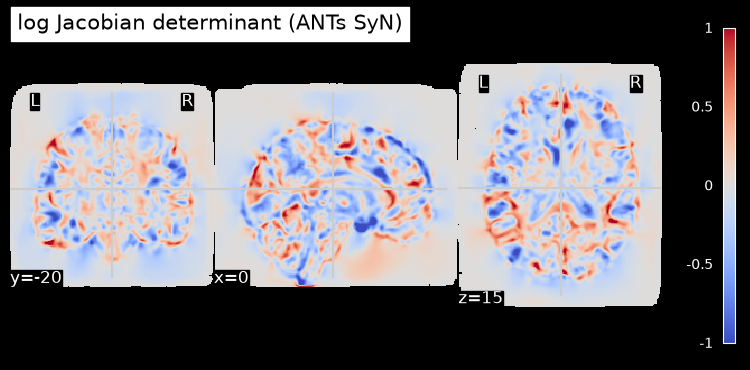

In [24]:
# Visual check of the deformation (not in the report): log-Jacobian, 0 = no volume change
log_jac = nib.Nifti1Image(np.log(nib.load(jac_path).get_fdata().clip(1e-3)),
                          nib.load(jac_path).affine)
plotting.plot_stat_map(log_jac, bg_img=reference, cut_coords=CUT, cmap="coolwarm",
                       vmax=1, symmetric_cbar=True, black_bg=True,
                       title="log Jacobian determinant (ANTs SyN)")
plt.show()

In [25]:
# RUN: Apply the full SyN transform (affine + nonlinear warp) to the FAST segmentation
seg_mni = op.join(anat_out, "T1w_fast_seg_mni.nii.gz")

subprocess.run(["antsApplyTransforms", "-d", "3",
                "-i", segmentation_path + "_seg.nii.gz",       # FAST labels (1=CSF, 2=GM, 3=WM)
                "-r", reference,                                # MNI152 1 mm grid
                "-t", syn_full_prefix + "1Warp.nii.gz",         # nonlinear warp
                "-t", syn_full_prefix + "0GenericAffine.mat",   # affine
                "-n", "GenericLabel",                           # keeps integer labels
                "-o", seg_mni], check=True)


CompletedProcess(args=['antsApplyTransforms', '-d', '3', '-i', 'derivatives/anat/T1w_fast_seg.nii.gz', '-r', '/cvmfs/neurodesk.ardc.edu.au/containers/fsl_6.0.7.18_20250928/fsl_6.0.7.18_20250928.simg/opt/fsl-6.0.7.18//data/standard/MNI152_T1_1mm_brain.nii.gz', '-t', 'derivatives/anat/T1w_to_mni_synfull_1Warp.nii.gz', '-t', 'derivatives/anat/T1w_to_mni_synfull_0GenericAffine.mat', '-n', 'GenericLabel', '-o', 'derivatives/anat/T1w_fast_seg_mni.nii.gz'], returncode=0)

## 2. Functional preprocessing

Motion correction, framewise displacement, Gaussian smoothing, and anatomical–functional alignment QC. Outputs are saved in `derivatives/func/` and `figures/`.

Requires the Neurodesk/FSL setup and the MNI-registered T1 from Section 1. Input preprocessing history remains unverified; motion estimated from previously corrected data represents residual realignment.

In [26]:
# Functional paths and acquisition information
import json
from shutil import which

os.makedirs(func_out, exist_ok=True)
fig_dir = "figures"
os.makedirs(fig_dir, exist_ok=True)
for command in ("mcflirt", "fslmaths"):
    if which(command) is None:
        raise RuntimeError(f"{command} unavailable: run the Neurodesk/FSL setup first.")

fmri_img = nib.load(fmri_path)
if len(fmri_img.shape) != 4 or fmri_img.shape[3] < 2:
    raise ValueError("Expected a 4D fMRI series with at least two volumes.")
n_volumes = fmri_img.shape[3]
tr_unit = fmri_img.header.get_xyzt_units()[1]
unit_scale = {"sec": 1., "msec": 1e-3, "usec": 1e-6}
if tr_unit not in unit_scale:
    raise ValueError("Unknown TR units: check the acquisition metadata first.")
TR = float(fmri_img.header.get_zooms()[3]) * unit_scale[tr_unit]
if not np.isfinite(TR) or TR <= 0:
    raise ValueError("TR must be positive and finite.")
frame_times = np.arange(n_volumes) * TR
volume_index = n_volumes // 2  # same volume for smoothing/alignment figures
CUT_FUNC = (0, -20, 15)       # coordinates in mm; inspect other cuts as well
func_prefix = op.join(func_out, "tfMRI_LANGUAGE_LR")
print(f"Volumes: {n_volumes}; TR: {TR:.3f} s; duration: {n_volumes * TR:.2f} s")
print(f"QC volume (zero-based): {volume_index}; time: {frame_times[volume_index]:.2f} s")
for label, path in [("T1 input", t1_path), ("fMRI input", fmri_path)]:
    img = nib.load(path)
    print(label, "qform/sform:", int(img.header["qform_code"]), int(img.header["sform_code"]))

Volumes: 316; TR: 0.720 s; duration: 227.52 s
QC volume (zero-based): 158; time: 113.76 s
T1 input qform/sform: 4 4
fMRI input qform/sform: 4 4


### 2.a. Motion correction and framewise displacement

MCFLIRT aligns each volume to the middle volume using six rigid-body parameters. All volumes are retained to preserve event timing. Power FD combines successive translations with rotations converted to displacement using a 50 mm radius. The first frame has no defined FD.

Motion outliers are screened using Q3 + 1.5 × IQR, following Lab 3. Candidate spike regressors are saved for subsequent GLM review.

Reference: [FSL MCFLIRT](https://fsl.fmrib.ox.ac.uk/fsl/docs/registration/mcflirt.html).

In [27]:
# RUN: rigid-body realignment, keeping the original temporal grid
moco_prefix = func_prefix + "_moco"
moco_path = moco_prefix + ".nii.gz"
subprocess.run(["mcflirt", "-in", fmri_path, "-out", moco_prefix,
                "-dof", "6", "-refvol", str(volume_index),
                "-plots", "-mats", "-report"], check=True)

corrected = nib.load(moco_path)
if corrected.shape != fmri_img.shape:
    raise ValueError("Motion correction changed the expected image dimensions.")
print("Motion-corrected image:", moco_path)

Processed data will be saved as derivatives/func/tfMRI_LANGUAGE_LR_moco

McFLIRT v 2.0 - FMRI motion correction

Reading time series... 
first iteration - 8mm scaling, set tolerance
Rescaling reference volume [158] to 8 mm pixels
Registering volumes ... [159][160][161][162][163][164][165][166][167][168][169][170][171][172][173][174][175][176][177][178][179][180][181][182][183][184][185][186][187][188][189][190][191][192][193][194][195][196][197][198][199][200][201][202][203][204][205][206][207][208][209][210][211][212][213][214][215][216][217][218][219][220][221][222][223][224][225][226][227][228][229][230][231][232][233][234][235][236][237][238][239][240][241][242][243][244][245][246][247][248][249][250][251][252][253][254][255][256][257][258][259][260][261][262][263][264][265][266][267][268][269][270][271][272][273][274][275][276][277][278][279][280][281][282][283][284][285][286][287][288][289][290][291][292][293][294][295][296][297][298][299][300][301][302][303][304][305][306][307][

refnum = 158
Original_refvol = 158



Saving motion corrected time series... 


Motion-corrected image: derivatives/func/tfMRI_LANGUAGE_LR_moco.nii.gz


In [28]:
# Power FD: sum of absolute successive translations and rotations (radius = 50 mm)
def compute_fd_power(parameters, radius_mm=50.0):
    parameters = np.asarray(parameters, dtype=float)
    if parameters.ndim != 2 or parameters.shape[1] != 6:
        raise ValueError("Expected (n_volumes, 6) MCFLIRT parameters.")
    if len(parameters) < 2 or not np.isfinite(parameters).all():
        raise ValueError("Need at least two rows of finite motion parameters.")
    delta = np.diff(parameters, axis=0)
    differences = (np.abs(delta[:, 3:]).sum(axis=1)
                   + radius_mm * np.abs(delta[:, :3]).sum(axis=1))
    # The first frame has no predecessor; leave it undefined in the QC table.
    return np.r_[np.nan, differences]

motion = np.loadtxt(moco_prefix + ".par", ndmin=2)
if motion.shape != (n_volumes, 6):
    raise ValueError(f"Unexpected motion-parameter shape: {motion.shape}")
fd = compute_fd_power(motion)

# Exploratory Tukey outlier threshold.
q25, q75 = np.quantile(fd[1:], [0.25, 0.75])
fd_threshold = q75 + 1.5 * (q75 - q25)
bad_motion = np.isfinite(fd) & (fd > fd_threshold)
bad_indices = np.flatnonzero(bad_motion)

motion_columns = ["rot_x", "rot_y", "rot_z", "trans_x", "trans_y", "trans_z"]
qc = pd.DataFrame(motion, columns=motion_columns)
qc.insert(0, "volume", np.arange(n_volumes))
qc.insert(1, "time_s", frame_times)
qc["framewise_displacement_mm"] = fd
qc["motion_outlier"] = bad_motion.astype(int)
qc.to_csv(func_prefix + "_motion_qc.tsv", sep="\t", index=False, na_rep="n/a")

# Candidate motion and spike regressors; retain the temporal grid.
motion_confounds = pd.DataFrame(motion, columns=motion_columns)
for idx in bad_indices:
    motion_confounds[f"motion_outlier_{idx:03d}"] = (np.arange(n_volumes) == idx).astype(int)
motion_confounds.to_csv(func_prefix + "_motion_confounds.tsv", sep="\t", index=False)
print(f"FD mean: {np.mean(fd[1:]):.4f} mm; max: {np.max(fd[1:]):.4f} mm")
print(f"Exploratory FD threshold: {fd_threshold:.4f} mm")
print(f"Flagged transitions: {len(bad_indices)}/{n_volumes - 1}")
print("Flagged volume indices (zero-based):", bad_indices.tolist())

FD mean: 0.0848 mm; max: 0.2592 mm
Exploratory FD threshold: 0.2334 mm
Flagged transitions: 3/315
Flagged volume indices (zero-based): [25, 26, 45]


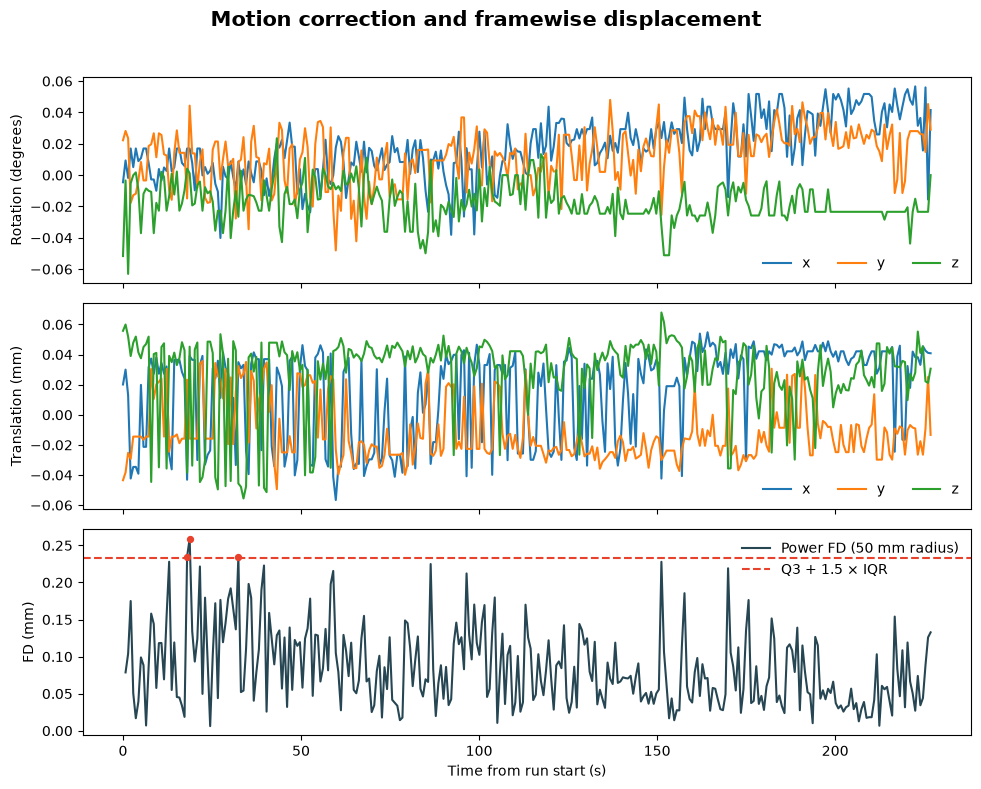

In [29]:
# Report figure: motion parameters and framewise displacement
fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
for j, axis in enumerate("xyz"):
    axes[0].plot(frame_times, np.rad2deg(motion[:, j]), label=axis)
    axes[1].plot(frame_times, motion[:, j + 3], label=axis)
axes[0].set_ylabel("Rotation (degrees)")
axes[1].set_ylabel("Translation (mm)")
for ax in axes[:2]:
    ax.legend(ncol=3, frameon=False)
axes[2].plot(frame_times, fd, color="#264653", label="Power FD (50 mm radius)")
axes[2].axhline(fd_threshold, color="#E8412C", ls="--", label="Q3 + 1.5 × IQR")
axes[2].scatter(frame_times[bad_motion], fd[bad_motion], color="#E8412C", s=18, zorder=3)
axes[2].set_ylabel("FD (mm)")
axes[2].set_xlabel("Time from run start (s)")
axes[2].legend(frameon=False)
fig.suptitle("Motion correction and framewise displacement", fontsize=15, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.96))
fig.savefig(op.join(fig_dir, "2a_motion_fd.png"), dpi=300, bbox_inches="tight")
plt.show()

#### Motion QC

Mean/max FD, flagged-frame count, and temporal distribution are reported below after execution. Flagged frames require visual review. FD does not measure all motion-related artifacts; candidate spike regressors require review before GLM fitting.

### 2.b. Gaussian smoothing

A 6 mm FWHM Gaussian kernel is applied to the motion-corrected series, following Lab 3. Spatial averaging trades fine detail for sensitivity to extended effects. FSL uses sigma in mm: $\sigma = \mathrm{FWHM}/\sqrt{8\ln 2} \approx 2.55$ mm.

The unsmoothed series is retained. No temporal filtering is applied at this stage.

FWHM = 6 mm; sigma = 2.548 mm


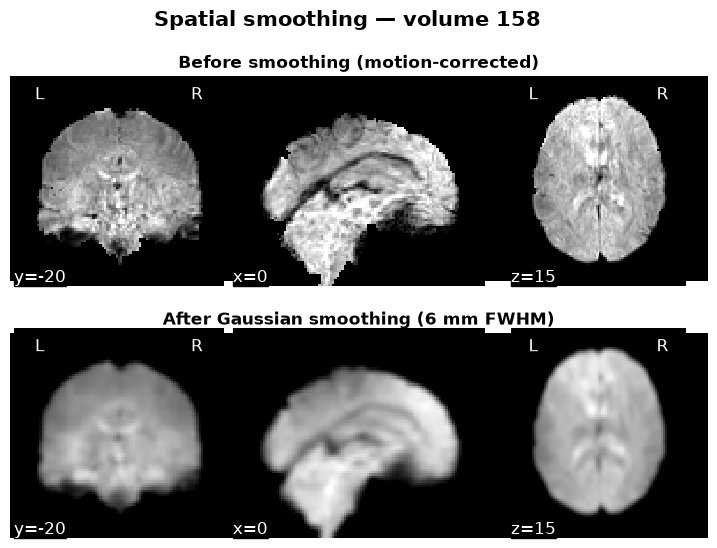

In [30]:
# RUN: Gaussian spatial smoothing, as in Lab 3
FWHM_MM = 6.0
sigma_mm = FWHM_MM / np.sqrt(8 * np.log(2))
smoothed_path = func_prefix + "_moco_smoothed-6mm.nii.gz"
subprocess.run(["fslmaths", moco_path, "-s", str(sigma_mm), smoothed_path], check=True)
smoothed = nib.load(smoothed_path)
if smoothed.shape != corrected.shape or not np.allclose(smoothed.affine, corrected.affine):
    raise ValueError("Unexpected spatial or temporal grid change during smoothing.")
print(f"FWHM = {FWHM_MM:g} mm; sigma = {sigma_mm:.3f} mm")

# Extract the same volume before and after smoothing.
volume_before = nib.Nifti1Image(np.asarray(corrected.dataobj[..., volume_index], dtype=np.float32),
                               corrected.affine)
volume_after = nib.Nifti1Image(np.asarray(smoothed.dataobj[..., volume_index], dtype=np.float32),
                              smoothed.affine)
nonzero = volume_before.get_fdata()
nonzero = nonzero[np.isfinite(nonzero) & (nonzero > 0)]
if not nonzero.size:
    raise ValueError("The selected fMRI volume has no positive finite signal.")
vmin, vmax = np.percentile(nonzero, [2, 98])
fig, axes = plt.subplots(2, 1, figsize=(9, 6))
for ax, image, label in zip(axes, [volume_before, volume_after],
                           ["Before smoothing (motion-corrected)", "After Gaussian smoothing (6 mm FWHM)"]):
    plotting.plot_anat(image, axes=ax, cut_coords=CUT_FUNC, draw_cross=False,
                       black_bg=True, vmin=vmin, vmax=vmax)
    ax.text(0.5, 1.02, label, transform=ax.transAxes,
            ha="center", va="bottom", fontsize=12, fontweight="bold")
fig.suptitle(f"Spatial smoothing — volume {volume_index}", fontsize=15, fontweight="bold", y=0.99)
fig.subplots_adjust(hspace=0.25)
fig.savefig(op.join(fig_dir, "2b_smoothing.png"), dpi=300, bbox_inches="tight")
plt.show()

#### Smoothing QC

The same volume is displayed before and after smoothing using identical coordinates and intensity limits. Spatial averaging reduces sharpness and mixes signal across tissue boundaries.

### 2.c. Anatomical–functional alignment

One unsmoothed, motion-corrected volume is overlaid on the selected MNI T1. Multiple axial levels are displayed; other orientations can be inspected in FSLeyes.

MNI header codes and grid dimensions alone do not establish anatomical correspondence. The T1-to-MNI warp is not applied to the functional series because the supplied fMRI may already be normalized.

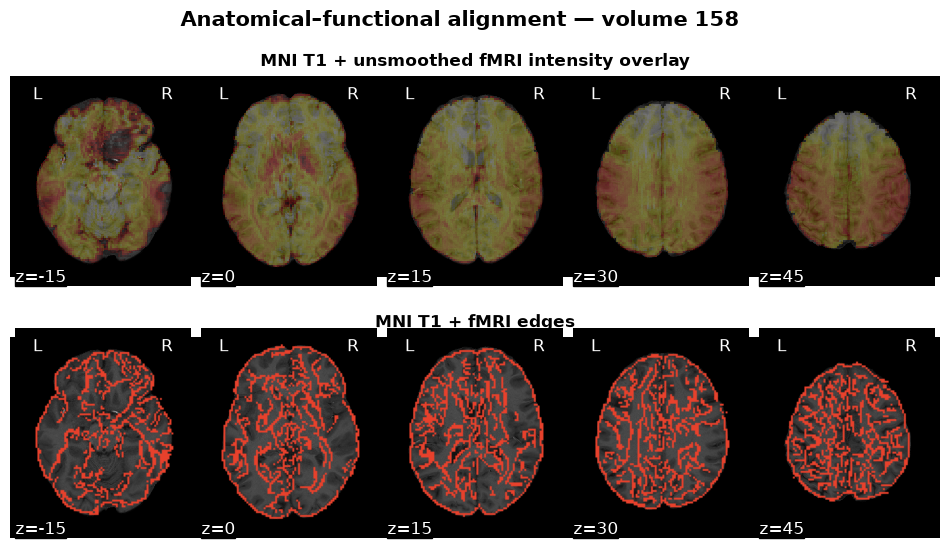

In [34]:
# Explicit choice: the selected anatomical result from Section 1
anat_mni_path = op.join(anat_out, "T1w_to_mni_synfull_Warped.nii.gz")
if not op.isfile(anat_mni_path):
    raise FileNotFoundError("Run structural registration first, or explicitly select your validated MNI T1.")
qc_volume_path = func_prefix + f"_moco_vol-{volume_index:03d}.nii.gz"
nib.save(volume_before, qc_volume_path)

# Display in world coordinates; no registration is estimated here.
z_cuts = [-15, 0, 15, 30, 45]
fig, axes = plt.subplots(2, 1, figsize=(12, 6))
disp = plotting.plot_anat(anat_mni_path, axes=axes[0], display_mode="z", cut_coords=z_cuts,
                          draw_cross=False, black_bg=True)
disp.add_overlay(volume_before, cmap="hot", threshold=float(vmin), alpha=0.25,
                 vmin=float(vmin), vmax=float(vmax), colorbar=False)
axes[0].text(0.5, 1.03, "MNI T1 + unsmoothed fMRI intensity overlay", transform=axes[0].transAxes,
             ha="center", va="bottom", fontsize=12, fontweight="bold")
disp = plotting.plot_anat(anat_mni_path, axes=axes[1], display_mode="z", cut_coords=z_cuts,
                          draw_cross=False, black_bg=True)
disp.add_edges(volume_before, color="#E8412C")
axes[1].text(0.5, 1.03, "MNI T1 + fMRI edges", transform=axes[1].transAxes,
             ha="center", va="bottom", fontsize=12, fontweight="bold")
fig.suptitle(f"Anatomical–functional alignment — volume {volume_index}",
             fontsize=15, fontweight="bold", y=0.99)
fig.subplots_adjust(hspace=0.3)
fig.savefig(op.join(fig_dir, "2c_anat_func_alignment.png"), dpi=300, bbox_inches="tight")
plt.show()

In [32]:
# Optional FSLeyes inspection
# fsleyesDisplay.resetOverlays()
# fsleyesDisplay.load(anat_mni_path)
# fsleyesDisplay.load(qc_volume_path)
# Check anatomical landmarks across slice levels.

#### Alignment QC

Visual alignment assessment: pending execution. Relevant landmarks include ventricles, outer brain boundaries, and cerebellum. Additional functional registration can be omitted only if anatomical correspondence is satisfactory. Signal dropout should be distinguished from displacement.

In [33]:
# Preprocessing outputs and QC metadata
fmri_preproc_path = smoothed_path
confounds_path = func_prefix + "_motion_confounds.tsv"
ALIGNMENT_APPROVED = False  # Manual visual-QC status

summary = {
    "input_fmri": fmri_path,
    "motion_corrected_fmri": moco_path,
    "smoothed_fmri": smoothed_path,
    "motion_qc": func_prefix + "_motion_qc.tsv",
    "candidate_glm_confounds": confounds_path,
    "TR_seconds": TR,
    "n_volumes": n_volumes,
    "discarded_initial_volumes": 0,
    "reference_volume_zero_based": volume_index,
    "smoothing_fwhm_mm": FWHM_MM,
    "fd_radius_mm": 50.0,
    "fd_threshold_rule": "Q3 + 1.5 * IQR (exploratory lab rule)",
    "fd_threshold_mm": float(fd_threshold),
    "flagged_volumes_zero_based": bad_indices.tolist(),
    "anatomical_reference": anat_mni_path,
    "additional_functional_registration_applied": False,
    "alignment_visually_approved": ALIGNMENT_APPROVED,
    "input_preprocessing_provenance": "unverified; assess whether motion estimates are residual"
}
with open(func_prefix + "_preprocessing_summary.json", "w") as file:
    json.dump(summary, file, indent=2)
print("Candidate GLM input:", fmri_preproc_path)
print("Candidate confounds:", confounds_path)
print("Alignment approved:", ALIGNMENT_APPROVED)
print("Before GLM: complete visual QC, review outlier handling, and verify event timing against the scan window.")

Candidate GLM input: derivatives/func/tfMRI_LANGUAGE_LR_moco_smoothed-6mm.nii.gz
Candidate confounds: derivatives/func/tfMRI_LANGUAGE_LR_motion_confounds.tsv
Alignment approved: False
Before GLM: complete visual QC, review outlier handling, and verify event timing against the scan window.


In [35]:
from pathlib import Path

print("Output folder:", Path(func_out).resolve())
print("Figures folder:", Path(fig_dir).resolve())

print(f"\nMean FD: {np.mean(fd[1:]):.4f} mm")
print(f"Maximum FD: {np.max(fd[1:]):.4f} mm")
print(f"FD threshold: {fd_threshold:.4f} mm")
print(f"Number of flagged volumes: {len(bad_indices)}")
print("Flagged volumes (zero-based):", bad_indices.tolist())

print("\nGenerated files:")
for path in sorted(Path(func_out).glob("*")):
    print(path.name)

Output folder: /home/jovyan/NSSP_lab1/derivatives/func
Figures folder: /home/jovyan/NSSP_lab1/figures

Mean FD: 0.0848 mm
Maximum FD: 0.2592 mm
FD threshold: 0.2334 mm
Number of flagged volumes: 3
Flagged volumes (zero-based): [25, 26, 45]

Generated files:
tfMRI_LANGUAGE_LR_moco.mat
tfMRI_LANGUAGE_LR_moco.nii.gz
tfMRI_LANGUAGE_LR_moco.par
tfMRI_LANGUAGE_LR_moco_smoothed-6mm.nii.gz
tfMRI_LANGUAGE_LR_moco_vol-158.nii.gz
tfMRI_LANGUAGE_LR_motion_confounds.tsv
tfMRI_LANGUAGE_LR_motion_qc.tsv
tfMRI_LANGUAGE_LR_preprocessing_summary.json


In [ ]:
Mean FD: 0.0848 mm
Maximum FD: 0.2592 mm
FD threshold: 0.2334 mm
Number of flagged volumes: 3
